# Промежуточная аттестация
Выполняю анализ ликвидности и платежеспособности. Проверяю способность организации рассчитаться по своим кратким и долгосрочным обязательствам.

## Ограничение выборки данных

In [110]:
import numpy as np
import pandas as pd
from datasets import load_dataset

dataset = load_dataset("irlspbru/RFSD", split="train", streaming=True)

selected_columns = [
    "inn",
    "line_1100",
    "line_1150",
    "line_1170",
    "line_1210",
    "line_1230",
    "line_1250",
    "line_1200",
    "line_1600",
    "line_1300",
    "line_1400",
    "line_1410",
    "line_1500",
    "line_1510",
    "line_1520",
    "line_1700",
    "line_2100",
    "line_2110",
    "line_2330",
    "line_2400",
]

data_subset = []
for row in dataset:
    # Собираю строки, где есть показатель активов (line_1600)
    if row.get("line_1600") is not None:
        filtered_row = {col: row.get(col) for col in selected_columns}
        data_subset.append(filtered_row)

        # Набираю ровно 1000 строк
        if len(data_subset) >= 1000:
            break

df = pd.DataFrame(data_subset)

df = df.fillna(0)

print("Размер:", df.shape)
display(df.head(1))

Размер: (1000, 20)


,inn,line_1100,line_1150,line_1170,line_1210,line_1230,line_1250,line_1200,line_1600,line_1300,line_1400,line_1410,line_1500,line_1510,line_1520,line_1700,line_2100,line_2110,line_2330,line_2400
0,4217064543,238.00,238.00,0.00,7 182.00,2 002.00,65.00,9 249.00,9 487.00,2 288.00,0.00,0.00,7 199.00,4 440.00,2 759.00,9 487.00,0.00,58 193.00,-271.00,-5 078.00


In [111]:
names_url = "https://raw.githubusercontent.com/irlcode/RFSD/main/aux_data/descriptive_names_dict.csv"
names_df = pd.read_csv(names_url)

rename_dict = dict(zip(names_df["original"], names_df["descriptive"]))

df = df.rename(columns=rename_dict)

inv_rename_dict = {v: k for k, v in rename_dict.items()}

for idx, col in enumerate(df.columns, start=1):
    old_name = inv_rename_dict.get(col, col)
    print(f"{idx}. {old_name} -> {col}")

1. inn -> inn
2. line_1100 -> B_noncurrent_assets
3. line_1150 -> B_fixed_assets
4. line_1240 -> B_fin_invest
5. line_1210 -> B_inventories
6. line_1230 -> B_accounts_receivable
7. line_1250 -> B_cash_equivalents
8. line_1200 -> B_current_assets
9. line_1600 -> B_assets
10. line_1300 -> B_total_equity
11. line_1400 -> B_longterm_liab
12. line_1410 -> B_longterm_debt
13. line_1500 -> B_shortterm_liab
14. line_1510 -> B_shortterm_debt
15. line_1520 -> B_shortterm_payables
16. line_1700 -> B_liab
17. line_2100 -> PL_gross_profit
18. line_2110 -> PL_revenue
19. line_2330 -> PL_interest_payable
20. line_2400 -> PL_net_profit


In [112]:
display(df.head(1))

,inn,B_noncurrent_assets,B_fixed_assets,B_fin_invest,B_inventories,B_accounts_receivable,B_cash_equivalents,B_current_assets,B_assets,B_total_equity,B_longterm_liab,B_longterm_debt,B_shortterm_liab,B_shortterm_debt,B_shortterm_payables,B_liab,PL_gross_profit,PL_revenue,PL_interest_payable,PL_net_profit
0,4217064543,238.00,238.00,0.00,7 182.00,2 002.00,65.00,9 249.00,9 487.00,2 288.00,0.00,0.00,7 199.00,4 440.00,2 759.00,9 487.00,0.00,58 193.00,-271.00,-5 078.00


### Вывод  
  - По условию задания установлено ограничение 20 финансовых показателей для 1000 организаций.
  - Дополнительно применён фильтр, в выборку попадали только организации, у которых заполнен показатель активов `line_1600`, `B_assets`.
  - Пропуски заполнены нулями.
  - Это позволило работать с сопоставимыми данными и исключить организации без балансовой информации.

## Описательная статистика

In [113]:
pd.set_option('display.float_format', lambda x: f'{x:,.2f}'.replace(',', ' '))

desc_stats = df.describe().T.style.format('{:,.2f}')
display(desc_stats)

,count,mean,std,min,25%,50%,75%,max
B_noncurrent_assets,"1,000.00","22,274.18","198,572.12",0.00,0.00,0.00,529.25,"4,817,013.00"
B_fixed_assets,"1,000.00","10,515.99","75,900.27",0.00,0.00,0.00,336.00,"1,916,828.00"
B_fin_invest,"1,000.00","10,607.83","167,932.86",0.00,0.00,0.00,0.00,"4,528,557.00"
B_inventories,"1,000.00","10,872.16","77,141.56",0.00,10.00,291.00,"2,659.25","1,566,870.00"
B_accounts_receivable,"1,000.00","33,513.73","315,904.83",0.00,65.75,840.00,"5,827.00","7,625,837.00"
B_cash_equivalents,"1,000.00","2,306.98","28,130.03",0.00,2.00,48.00,428.75,"865,632.00"
B_current_assets,"1,000.00","65,076.50","822,265.56",0.00,309.25,"2,373.50","13,226.50","24,635,889.00"
B_assets,"1,000.00","87,357.56","893,921.02",1.00,360.00,"2,771.00","17,083.50","24,683,982.00"
B_total_equity,"1,000.00","15,699.26","125,770.67","-206,256.00",11.00,190.50,"1,488.25","2,289,199.00"
B_longterm_liab,"1,000.00","16,037.74","253,493.16",0.00,0.00,0.00,0.00,"7,521,560.00"


In [114]:
cols_to_check = ["B_assets", "PL_revenue", "PL_net_profit"]

skew_summary = pd.DataFrame({
    "Среднее (mean)": df[cols_to_check].mean(),
    "Медиана (median)": df[cols_to_check].median(),
    "Кратность (mean / median)": df[cols_to_check].mean() / df[cols_to_check].median(),
    "Коэффициент асимметрии (skew)": df[cols_to_check].skew()
})

display(skew_summary.round(2))


,Среднее (mean),Медиана (median),Кратность (mean / median),Коэффициент асимметрии (skew)
B_assets,87 357.56,2 771.00,31.53,23.07
PL_revenue,138 283.92,7 077.50,19.54,22.76
PL_net_profit,10 476.00,54.00,194.00,30.86


In [115]:
neg_equity = df[df['B_total_equity'] < 0]
neg_profit = df[df['PL_net_profit'] < 0]

print(f"Минимальный капитал (B_total_equity): {df['B_total_equity'].min():,.0f} тыс. руб.")
print(f"Организаций с отрицательным капиталом: {len(neg_equity)} ({len(neg_equity)/len(df)*100:.1f}%)\n")

print(f"Минимальная чистая прибыль (PL_net_profit): {df['PL_net_profit'].min():,.0f} тыс. руб.")
print(f"Максимальная чистая прибыль (PL_net_profit): {df['PL_net_profit'].max():,.0f} тыс. руб.")
print(f"Количество убыточных организаций: {len(neg_profit)} ({len(neg_profit)/len(df)*100:.1f}%)\n")

print(f"Максимальная процентная нагрузка / мин. PL_interest_payable: {df['PL_interest_payable'].min():,.0f} тыс. руб.")

Минимальный капитал (B_total_equity): -206,256 тыс. руб.
Организаций с отрицательным капиталом: 140 (14.0%)

Минимальная чистая прибыль (PL_net_profit): -403,414 тыс. руб.
Максимальная чистая прибыль (PL_net_profit): 8,300,803 тыс. руб.
Количество убыточных организаций: 182 (18.2%)

Максимальная процентная нагрузка / мин. PL_interest_payable: -140,793 тыс. руб.


In [122]:
for col in cols_to_check:
    q25 = df[col].quantile(0.25)
    q75 = df[col].quantile(0.75)
    iqr = q75 - q25
    upper_bound = q75 + 1.5 * iqr
    outliers = df[df[col] > upper_bound]
    print(f"Показатель [{col}]: Порог выброса = {upper_bound:,.0f} | Число выбросов = {len(outliers)} ({len(outliers)/len(df)*100:.1f}%)")

Показатель [B_assets]: Порог выброса = 42,169 | Число выбросов = 147 (14.7%)
Показатель [PL_revenue]: Порог выброса = 94,211 | Число выбросов = 119 (11.9%)
Показатель [PL_net_profit]: Порог выброса = 1,231 | Число выбросов = 158 (15.8%)


In [121]:
zero_share = (df[[
    "B_noncurrent_assets",
    "B_longterm_liab",
    "B_fin_invest"
]] == 0).mean() * 100

display(zero_share.round(1))

,0
B_noncurrent_assets,53.30
B_longterm_liab,84.60
B_fin_invest,85.00


### Вывод
  - Распределения всех показателей асимметричны, среднее больше медианы.
  - Присутствуют крупные выбросы.
  - Многие показатели внеоборотных активов `B_noncurrent_assets`, долгосрочных обязательств `B_longterm_liab` и финансовых вложений `B_fin_invest` у большинства равны нулю.

## Гистограммы и выбросы



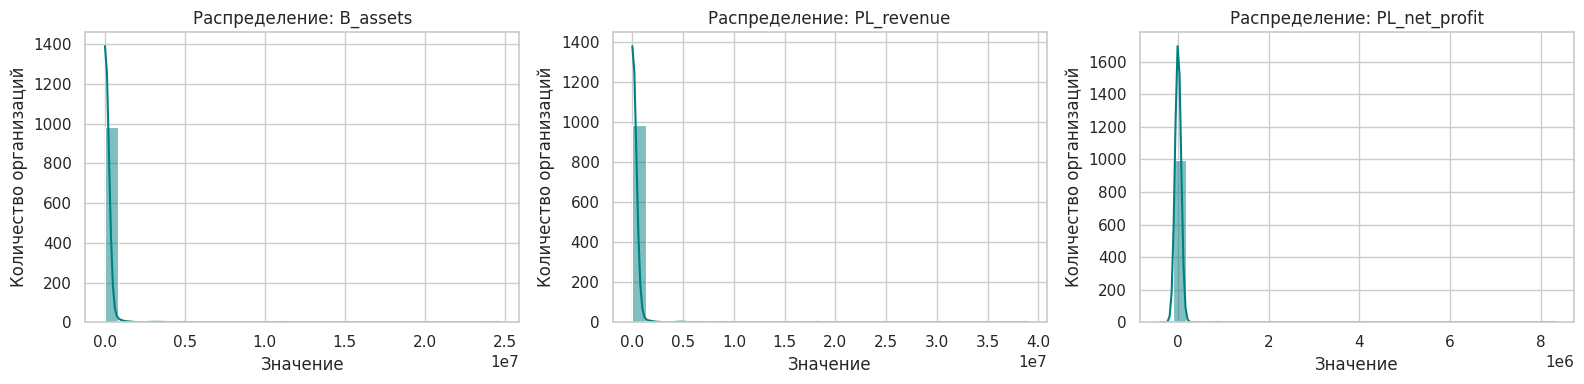

In [117]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

cols_to_plot = ["B_assets", "PL_revenue", "PL_net_profit"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for i, col in enumerate(cols_to_plot):
  sns.histplot(df[col], bins=30, ax=axes[i], color="teal", kde=True)
  axes[i].set_title(f"Распределение: {col}")
  axes[i].set_xlabel("Значение")
  axes[i].set_ylabel("Количество организаций")
  axes[i].grid(True)

plt.tight_layout()
plt.show()

### Вывод
  - Показатели имеют правостороннюю асимметрию: активы `B_assets`, выручка `PL_revenue`, чистая прибыль `PL_net_profit`.
  - Основная масса организаций сосредоточена в области малых значений, а небольшой процент крупных организаций формирует длинный хвост.
  - Это указывает на наличие крупных выбросов.

## Матрица корреляции



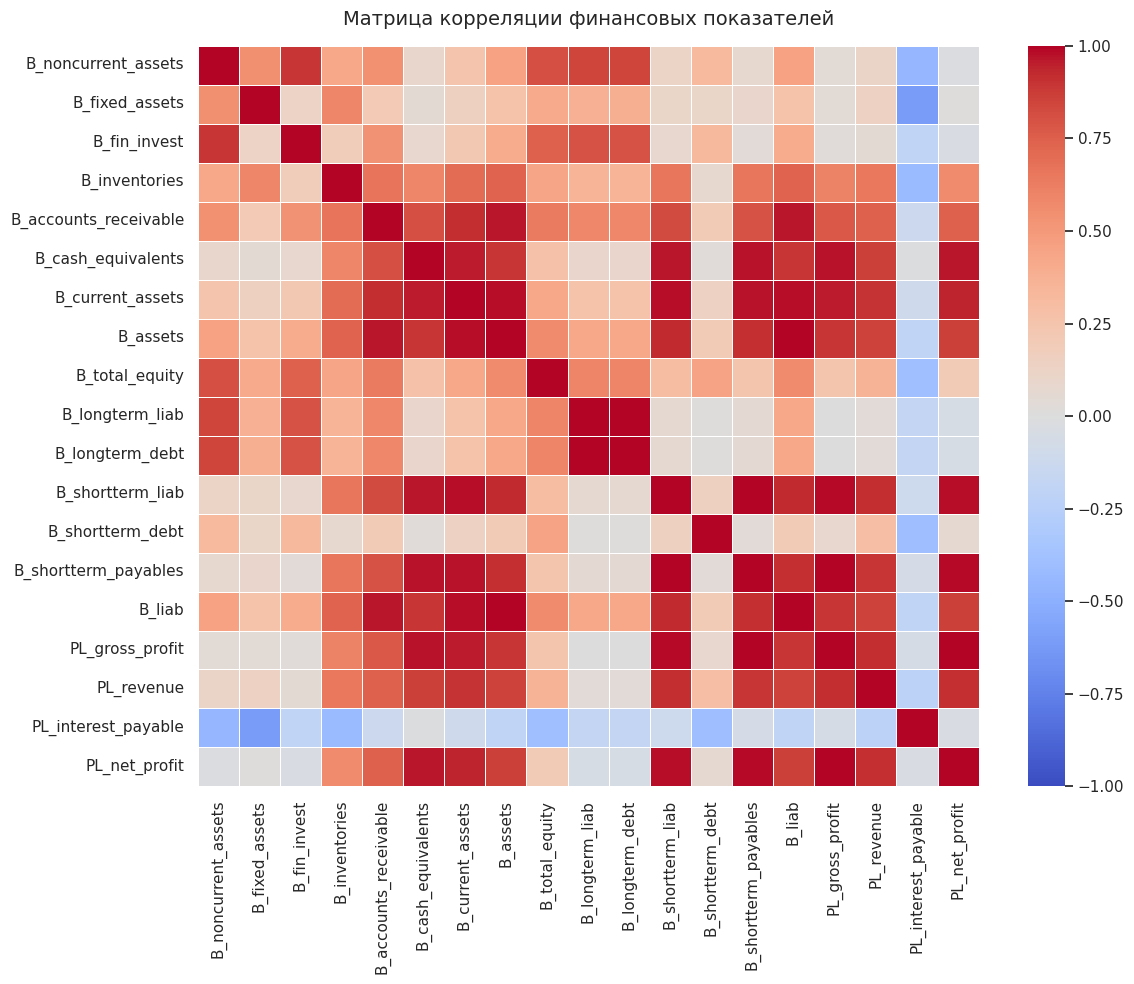

In [118]:
plt.figure(figsize=(12, 10))

numeric_df = df.select_dtypes(include=["number"])
corr_matrix = numeric_df.corr()

sns.heatmap(
    corr_matrix, annot=False, cmap="coolwarm", linewidths=0.5, vmin=-1, vmax=1
)

plt.title(
    "Матрица корреляции финансовых показателей",
    fontsize=14,
    pad=15,
)
plt.tight_layout()
plt.show()

In [119]:
corr_pairs = (
    corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    .stack()
    .sort_values(ascending=False)
)
print("Топ-10 положительных корреляций")
print(corr_pairs.head(10).round(3))

Топ-10 положительных корреляций
B_assets              B_liab                 1.00
B_longterm_liab       B_longterm_debt        1.00
PL_gross_profit       PL_net_profit          1.00
B_shortterm_liab      B_shortterm_payables   0.99
B_shortterm_payables  PL_gross_profit        0.99
B_shortterm_liab      PL_gross_profit        0.99
B_shortterm_payables  PL_net_profit          0.99
B_shortterm_liab      PL_net_profit          0.98
B_current_assets      B_shortterm_liab       0.98
                      B_liab                 0.98
dtype: float64


### Вывод
Наиболее сильная положительная корреляция наблюдается между:
- `B_assets` и `B_current_assets` итоговые активы в основном складываются из оборотных
- `B_assets` и `PL_revenue` крупные организации имеют большую выручку
- `B_shortterm_liab` и `B_shortterm_payables` краткосрочные обязательства во многом состоят из кредиторской задолженности

Слабая корреляция у собственного капитала `B_total_equity` и долгосрочных обязательств `B_longterm_liab` у большинства организаций эти показатели близки к нулю.

## Диаграмма рассеивания



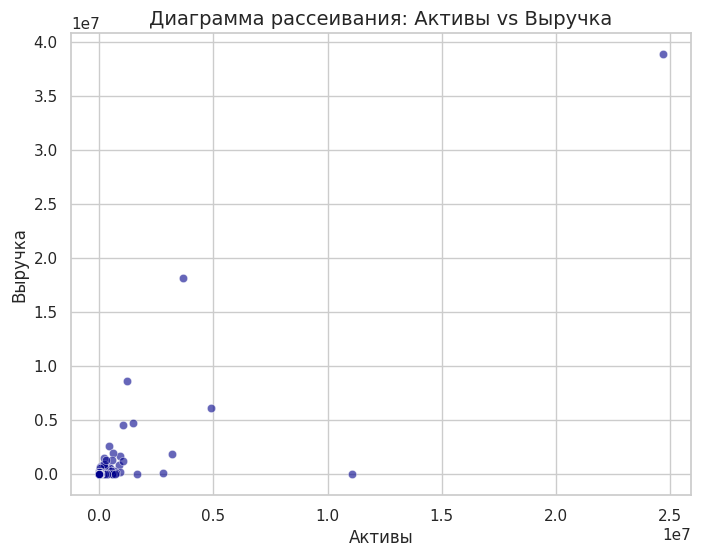

In [120]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x="B_assets",
    y="PL_revenue",
    alpha=0.6,
    color="darkblue",
)

plt.title("Диаграмма рассеивания: Активы vs Выручка", fontsize=14)
plt.xlabel("Активы")
plt.ylabel("Выручка")
plt.grid(True)
plt.show()

### Вывод
- Наблюдается положительная связь между размером активов `B_assets` и выручкой `PL_revenue`, организации с большими активами имеют более высокую выручку
- Основная масса точек лежит в области малых значений, крупные организации образуют отдельные скопления справа вверху

## Итоговый вывод

План работы
1. Ограничение выборки данных
1. Описательная статистика
1. Гистограммы и выбросы
1. Матрица корреляции
1. Диаграмма рассеивания

- Целью было оценить способность компаний рассчитываться по краткосрочным и долгосрочным обязательствам, средние значения по выборке искажены крупными организациями, поэтому подробынй анализ лучше провести с учётом размера организации
- В ходе анализа выявлены сильная асимметрия финансовых показателей, наличие выбросов и высокая корреляция между рядом показателей, обусловленная их структурной взаимосвязью
- Также обнаружены организации с отрицательным капиталом и убытками, что указывает на наличие финансово неблагополучных компаний в выборке